In [110]:
import numpy as np
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [111]:
df_dirty = df.copy()

df_dirty.loc[1, "deck"] = np.nan
df_dirty.loc[3] = df_dirty.loc[2]
df_dirty.loc[0, "sex"] = "test"
df_dirty.loc[0, "age"] = -1

df_dirty.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,test,-1.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,NaN,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [112]:
df_dirty.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           690
embark_town      2
alive            0
alone            0
dtype: int64

In [113]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [114]:
df.value_counts(["sex"])
df_dirty.value_counts(["sex"])

sex   
male      576
female    314
test        1
Name: count, dtype: int64

In [115]:
df_dirty.duplicated().sum()

df.duplicated().sum()

np.int64(107)

In [116]:
print(df.value_counts(["survived", "alive"]))
print(df.value_counts(["survived"]))

survived  alive
0         no       549
1         yes      342
Name: count, dtype: int64
survived
0           549
1           342
Name: count, dtype: int64


In [117]:
print(df.value_counts(["pclass", "class"]))
print(df.value_counts(["pclass"]))

pclass  class 
3       Third     491
1       First     216
2       Second    184
3       First       0
        Second      0
1       Third       0
        Second      0
2       Third       0
        First       0
Name: count, dtype: int64
pclass
3         491
1         216
2         184
Name: count, dtype: int64


In [118]:
print(df.value_counts(["embarked", "embark_town"]))
print(df.value_counts(["embarked"]))

embarked  embark_town
S         Southampton    644
C         Cherbourg      168
Q         Queenstown      77
Name: count, dtype: int64
embarked
S           644
C           168
Q            77
Name: count, dtype: int64


In [119]:
df.drop(columns=["embarked", "pclass", "alive"])
df.drop_duplicates()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [120]:
import pandera as pa
from pandera import Check, Column, DataFrameSchema

titanic_schema = DataFrameSchema(
    columns={
        "survived": Column(int, Check.isin([0, 1]), nullable=False),
        "pclass": Column(int, Check.isin([1, 2, 3]), nullable=False),
        "sex": Column(str, Check.isin(["male", "female"]), nullable=False),
        "age": Column(
            float,
            Check.in_range(0, 120),
            nullable=True,  # 714 / 891 non-null
        ),
        "sibsp": Column(int, Check.ge(0), nullable=False),
        "parch": Column(int, Check.ge(0), nullable=False),
        "fare": Column(float, Check.ge(0), nullable=False),
        "embarked": Column(
            str,
            Check.isin(["C", "Q", "S"]),
            nullable=True,  # 889 / 891 non-null
        ),
        "class": Column(
            "category",
            Check.isin(["First", "Second", "Third"]),
            nullable=False,
        ),
        "who": Column(str, Check.isin(["man", "woman", "child"]), nullable=False),
        "adult_male": Column(bool, nullable=False),
        "deck": Column(
            "category",
            Check.isin(list("ABCDEFG")),
            nullable=True,  # 203 / 891 non-null
        ),
        "embark_town": Column(
            str,
            Check.isin(["Cherbourg", "Queenstown", "Southampton"]),
            nullable=True,  # 889 / 891 non-null
        ),
        "alive": Column(str, Check.isin(["no", "yes"]), nullable=False),
        "alone": Column(bool, nullable=False),
    },
    checks=[
        # spójność między kolumnami
        Check(
            lambda df: (df["alive"] == "yes") == (df["survived"] == 1),
            error="'alive' musi być zgodne z 'survived'",
        ),
        Check(
            lambda df: df["alone"] == ((df["sibsp"] + df["parch"]) == 0),
            error="'alone' musi być zgodne z sibsp + parch == 0",
        ),
        Check(
            lambda df: (
                df["class"].astype(str)
                == df["pclass"].map({1: "First", 2: "Second", 3: "Third"})
            ),
            error="'class' musi odpowiadać 'pclass'",
        ),
        Check(
            lambda df: df["embarked"].isna() == df["embark_town"].isna(),
            error="'embarked' i 'embark_town' muszą mieć braki w tych samych wierszach",
        ),
    ],
    strict=True,  # żadnych dodatkowych kolumn
    ordered=False,  # kolejność kolumn nieistotna
    coerce=False,
    name="TitanicSchema",
)

try:
    titanic_schema.validate(df_dirty, lazy=True)
    print("Walidacja zakończona powodzeniem")
except pa.errors.SchemaErrors as err:  # type: ignore
    print(err.failure_cases)

try:
    titanic_schema.validate(df, lazy=True)
    print("Walidacja zakończona powodzeniem")
except pa.errors.SchemaErrors as err:  # type: ignore
    print(err.failure_cases)

  schema_context column                     check  check_number failure_case  \
0         Column    sex  isin(['male', 'female'])             0         test   
1         Column    age          in_range(0, 120)             0         -1.0   

   index  
0      0  
1      0  
Walidacja zakończona powodzeniem


In [121]:
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    RobustScaler,
    StandardScaler,
)

OH_COLUMNS = ["sex", "embarked", "who", "embark_town", "alive"]

oh = OneHotEncoder()

encoded = pd.DataFrame(
    oh.fit_transform(df[OH_COLUMNS]).toarray(),  # type: ignore
    columns=oh.get_feature_names_out(OH_COLUMNS),
    index=df.index,
)

df_oh = pd.concat([df.drop(columns=OH_COLUMNS), encoded], axis=1)

df_oh.head()

,survived,pclass,age,sibsp,parch,fare,class,adult_male,deck,alone,...,embarked_nan,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton,embark_town_nan,alive_no,alive_yes
0,0,3,22.0,1,0,7.2500,Third,True,NaN,False,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1,1,38.0,1,0,71.2833,First,False,C,False,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1,3,26.0,0,0,7.9250,Third,False,NaN,True,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1,1,35.0,1,0,53.1000,First,False,C,False,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0,3,35.0,0,0,8.0500,Third,True,NaN,True,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [122]:
ORD_COLUMNS = ["sex", "embarked", "who", "embark_town", "alive"]

ordinal = OrdinalEncoder()  # nie nazywaj zmiennej `ord`, to wbudowana funkcja Pythona

encoded = pd.DataFrame(
    ordinal.fit_transform(df[ORD_COLUMNS]),
    columns=ORD_COLUMNS,
    index=df.index,
)

df_ord = pd.concat([df.drop(columns=ORD_COLUMNS), encoded], axis=1)
df_ord.head()

,survived,pclass,age,sibsp,parch,fare,class,adult_male,deck,alone,sex,embarked,who,embark_town,alive
0,0,3,22.0,1,0,7.2500,Third,True,NaN,False,1.0,2.0,1.0,2.0,0.0
1,1,1,38.0,1,0,71.2833,First,False,C,False,0.0,0.0,2.0,0.0,1.0
2,1,3,26.0,0,0,7.9250,Third,False,NaN,True,0.0,2.0,2.0,2.0,1.0
3,1,1,35.0,1,0,53.1000,First,False,C,False,0.0,2.0,2.0,2.0,1.0
4,0,3,35.0,0,0,8.0500,Third,True,NaN,True,1.0,2.0,1.0,2.0,0.0


In [123]:
std = StandardScaler()
min_max = MinMaxScaler()
robust = RobustScaler()

COLUMNS = ["age", "fare"]

df_std = df.copy()
df_std[COLUMNS] = std.fit_transform(df_std[COLUMNS])
print("STD\n", df_std.head())

df_min_max = df.copy()
df_min_max[COLUMNS] = min_max.fit_transform(df_min_max[COLUMNS])
print("MIN MAX\n", df_min_max.head())

df_robust = df.copy()
df_robust[COLUMNS] = robust.fit_transform(df_robust[COLUMNS])
print("ROBUST\n", df_robust.head())

STD
    survived  pclass     sex       age  sibsp  parch      fare embarked  class  \
0         0       3    male -0.530377      1      0 -0.502445        S  Third   
1         1       1  female  0.571831      1      0  0.786845        C  First   
2         1       3  female -0.254825      0      0 -0.488854        S  Third   
3         1       1  female  0.365167      1      0  0.420730        S  First   
4         0       3    male  0.365167      0      0 -0.486337        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
MIN MAX
    survived  pclass     sex       age  sibsp  parch      fare embarked  class  \
0         0       3    male  0.271174      1      0  0.014151        S  Third   
1         1  

In [124]:
ordinal = OrdinalEncoder(categories=[["First", "Second", "Third"]])

PCA_COLUMNS = ["age", "fare", "sibsp", "parch"]

class_encoded = pd.DataFrame(
    ordinal.fit_transform(df[["class"]]),
    columns=["class_enc"],
    index=df.index,
)

X = pd.concat([df[PCA_COLUMNS], class_encoded], axis=1)

X.head()

,age,fare,sibsp,parch,class_enc
0,22.0,7.2500,1,0,2.0
1,38.0,71.2833,1,0,0.0
2,26.0,7.9250,0,0,2.0
3,35.0,53.1000,1,0,0.0
4,35.0,8.0500,0,0,2.0


In [125]:
X.corr()

,age,fare,sibsp,parch,class_enc
age,1.000000,0.096067,-0.308247,-0.189119,-0.369226
fare,0.096067,1.000000,0.159651,0.216225,-0.549500
sibsp,-0.308247,0.159651,1.000000,0.414838,0.083081
parch,-0.189119,0.216225,0.414838,1.000000,0.018443
class_enc,-0.369226,-0.549500,0.083081,0.018443,1.000000


In [130]:
std = StandardScaler()

X_std = X.copy()
X_std = X_std.dropna()
X_std[PCA_COLUMNS] = std.fit_transform(X_std[PCA_COLUMNS])

X_std.head()

,age,fare,sibsp,parch,class_enc
0,-0.530377,-0.518978,0.524570,-0.505895,2.0
1,0.571831,0.691897,0.524570,-0.505895,0.0
2,-0.254825,-0.506214,-0.551703,-0.505895,2.0
3,0.365167,0.348049,0.524570,-0.505895,0.0
4,0.365167,-0.503850,-0.551703,-0.505895,2.0


In [136]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pd.DataFrame(pca.fit_transform(X_std))
X_pca

,0,1,2,3,4
0,0.377468,-1.039158,-0.353878,0.496863,0.264465
1,-0.373758,1.315833,-0.417647,0.800336,-0.424442
2,-0.427344,-1.038975,-0.171846,-0.243701,0.336326
3,-0.307019,0.996845,-0.414918,0.788551,-0.658082
4,-0.747577,-0.822477,0.224534,-0.013614,0.494178
...,...,...,...,...,...
709,2.435368,0.862268,4.013239,-2.687437,0.112594
710,-0.613083,-0.395092,-0.312479,-0.174873,-0.398763
711,-0.452017,0.196236,-0.939066,-0.379246,-1.171465
712,-0.701301,0.363301,-0.630047,-0.199941,-1.049661


In [ ]:
var = pd.DataFrame(
    {
        "wariancja": pca.explained_variance_ratio_,
        "skumulowana": np.cumsum(pca.explained_variance_ratio_),
    },
    index=X_pca.columns,
)
print(var.round(3))
print("Składowych na 80%:", np.argmax(var["skumulowana"] >= 0.8) + 1)

pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]

loadings = pd.DataFrame(
    pca.components_.T,
    index=X_std.columns,
    columns=pc_names,
)
print(loadings[["PC1", "PC2"]].round(3))

   wariancja  skumulowana
0      0.350        0.350
1      0.316        0.666
2      0.146        0.812
3      0.125        0.937
4      0.063        1.000
Składowych na 80%: 3
             PC1    PC2
age       -0.517  0.346
fare       0.117  0.719
sibsp      0.617  0.097
parch      0.559  0.222
class_enc  0.161 -0.551


Przed augmentacją: 571
Szum 2%: po augmentacji 1142
Szum 50%: po augmentacji 1142


/tmp/ipykernel_6014/1505649712.py:34: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(


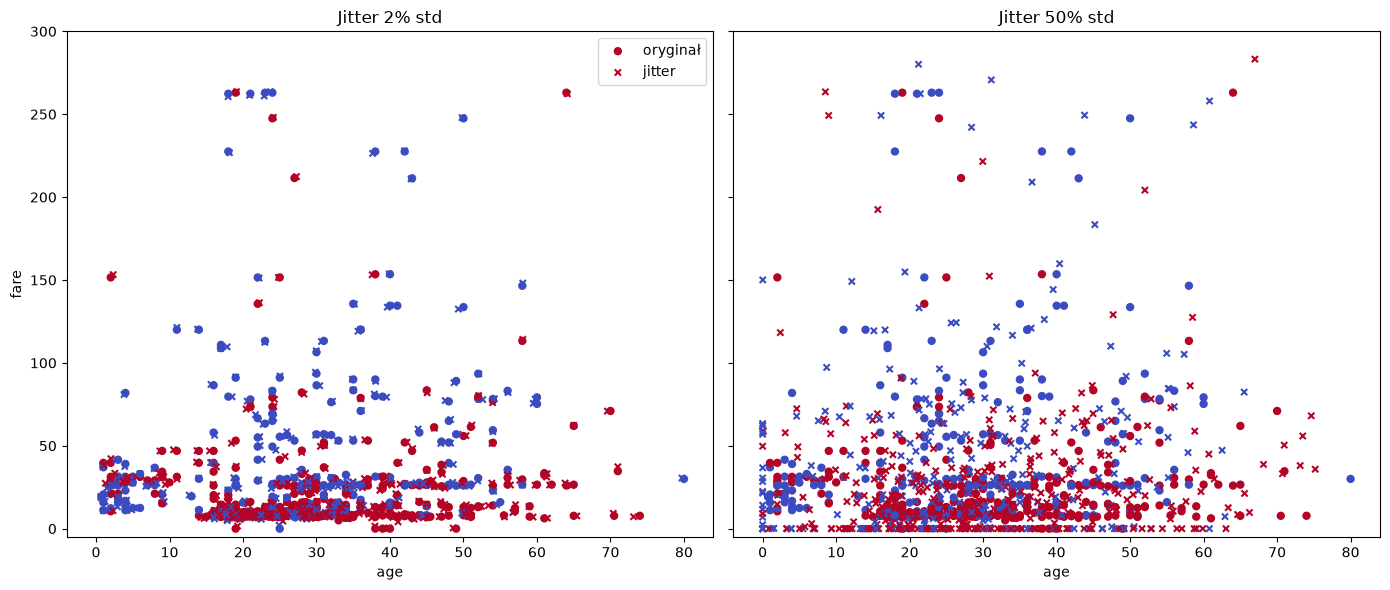

In [140]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

data = sns.load_dataset("titanic")[["age", "fare", "survived"]].dropna()

X_train, X_test, y_train, y_test = train_test_split(
    data[["age", "fare"]],
    data["survived"],
    test_size=0.2,
    stratify=data["survived"],
    random_state=42,
)
print("Przed augmentacją:", len(X_train))

std = X_train.std()
rng = np.random.default_rng(42)


def jitter(X, noise_pct):
    noise = rng.normal(0, noise_pct * std.values, size=X.shape)
    return (X + noise).clip(lower=0)  # bez ujemnych wartości


fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, pct in zip(axes, (0.02, 0.50)):
    X_aug = jitter(X_train, pct)
    y_aug = y_train.copy()  # etykiety bez zmian

    X_all = pd.concat([X_train, X_aug])
    y_all = pd.concat([y_train, y_aug])
    print(f"Szum {pct:.0%}: po augmentacji {len(X_all)}")

    ax.scatter(
        X_train["age"],
        X_train["fare"],
        c=y_train,
        cmap="coolwarm_r",
        marker="o",
        facecolors="none",
        s=25,
        label="oryginał",
    )
    ax.scatter(
        X_aug["age"],
        X_aug["fare"],
        c=y_aug,
        cmap="coolwarm_r",
        marker="x",
        s=20,
        label="jitter",
    )
    ax.set_title(f"Jitter {pct:.0%} std")
    ax.set_xlabel("age")
    ax.set_ylim(-5, 300)

axes[0].set_ylabel("fare")
axes[0].legend()
plt.tight_layout()
plt.show()